# Name That LLM — TF-IDF + LinearSVC

Compare `char`, `word`, and combined TF-IDF features using prompt-grouped cross-validation.


## 1. Load data

Inspect columns, classes, and unique prompts.


In [3]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
)
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import FeatureUnion, make_pipeline
from sklearn.svm import LinearSVC

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

train_path = PROJECT_ROOT / "data" / "train.csv"
train_df = pd.read_csv(train_path).reset_index(drop=True)

required_columns = {"text", "model", "prompt_id"}
missing = required_columns - set(train_df.columns)
if missing:
    raise ValueError(f"Missing columns in train.csv: {sorted(missing)}")

print("Shape:", train_df.shape)
print("Unique prompts:", train_df["prompt_id"].nunique())
display(train_df.head(3))
display(train_df["model"].value_counts().rename("count"))

Shape: (2699, 4)
Unique prompts: 150


,id,prompt_id,text,model
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max
1,0041ac86ee93,p073,Data science communities matter because they a...,claude-sonnet-5
2,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash


model
qwen3.8-max               150
claude-sonnet-5           150
gemini-3.6-flash          150
gpt-5.6-terra             150
glm-5.3-flash             150
gemini-3.1-pro-preview    150
gemini-3.8-flash          150
claude-opus-4-6           150
gpt-5.6-luna              150
claude-opus-4-8           150
gemini-3.7-flash          150
claude-opus-5             150
kimi-k3                   150
gpt-5.5                   150
gpt-6-astra               150
glm-5.3                   150
gpt-5.6-sol               150
claude-fable-5            149
Name: count, dtype: int64

## 2. Models

Build `char`, `word`, and combined TF-IDF pipelines. `word_weight` controls the contribution of word features.


In [4]:
def build_model(kind: str, word_weight: float = 1.0):
    char_vectorizer = TfidfVectorizer(
        analyzer="char",
        ngram_range=(2, 5),
        min_df=2,
        sublinear_tf=True,
        max_features=100_000,
    )
    word_vectorizer = TfidfVectorizer(
        analyzer="word",
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True,
        max_features=40_000,
    )

    if kind == "char":
        features = char_vectorizer
    elif kind == "word":
        features = word_vectorizer
    elif kind == "both":
        features = FeatureUnion(
            [("char", char_vectorizer), ("word", word_vectorizer)],
            transformer_weights={"char": 1.0, "word": word_weight},
        )
    else:
        raise ValueError(f"Unknown feature type: {kind}")

    return make_pipeline(features, LinearSVC(C=1.0, max_iter=5000))


# Define all experiments in one place.
# Add a new weight without duplicating training code.
MODEL_CONFIGS = {
    "char": {"kind": "char"},
    "word": {"kind": "word"},
    "both_w1.0": {"kind": "both", "word_weight": 1.0},
    "both_w0.3": {"kind": "both", "word_weight": 0.3},
}

## 3. Cross-validation and OOF predictions

Use `GroupKFold(prompt_id)` to avoid sharing prompts between train and validation. Save predictions for error analysis.


In [5]:
X = train_df["text"].fillna("")
y = train_df["model"]
groups = train_df["prompt_id"]

cv = GroupKFold(n_splits=5)
folds = list(cv.split(X, y, groups=groups))

# Confirm there is no overlap in prompts between training and validation.
assert all(
    set(groups.iloc[train_idx]).isdisjoint(set(groups.iloc[val_idx]))
    for train_idx, val_idx in folds
)

predictions = {}  # {experiment_name: OOF predictions}
fold_results = []  # one row per model and fold

for name, params in MODEL_CONFIGS.items():
    oof = np.full(len(y), None, dtype=object)

    for fold_id, (train_idx, val_idx) in enumerate(folds):
        model = build_model(**params)  # fresh model for this fold
        model.fit(X.iloc[train_idx], y.iloc[train_idx])
        pred = model.predict(X.iloc[val_idx])

        oof[val_idx] = pred  # preserve original row order
        fold_results.append({
            "model": name,
            "fold": fold_id,
            "balanced_accuracy": balanced_accuracy_score(y.iloc[val_idx], pred),
        })

    assert all(value is not None for value in oof), "Not every row received an OOF prediction"
    predictions[name] = oof

fold_scores = pd.DataFrame(fold_results)

# Summary table: std(ddof=0), matching the original np.std(scores).
summary = (
    fold_scores.groupby("model")["balanced_accuracy"]
    .agg(mean_score="mean", std_score=lambda scores: scores.std(ddof=0))
    .sort_values("mean_score", ascending=False)
)

print("Per-fold scores:")
display(fold_scores.pivot(index="fold", columns="model", values="balanced_accuracy"))
print("Summary scores:")
display(summary)

Per-fold scores:


model,both_w0.3,both_w1.0,char,word
fold,,,,
0,0.298148,0.292593,0.301852,0.231481
1,0.285185,0.298148,0.294444,0.262963
2,0.318519,0.311111,0.325926,0.262963
3,0.325926,0.320370,0.327778,0.281481
4,0.324393,0.311303,0.328097,0.275990


Summary scores:


,mean_score,std_score
model,,
char,0.315619,0.014475
both_w0.3,0.310434,0.016054
both_w1.0,0.306705,0.009997
word,0.262976,0.017342


### Evaluate results

Compare balanced accuracy across the same folds. Lower standard deviation does not necessarily mean a better model.


In [6]:
# Positive values mean Char outperformed the specified combined model on this fold.
fold_table = fold_scores.pivot(
    index="fold", columns="model", values="balanced_accuracy"
)

comparison_by_fold = pd.DataFrame({
    "char_minus_both_w1.0": fold_table["char"] - fold_table["both_w1.0"],
    "char_minus_both_w0.3": fold_table["char"] - fold_table["both_w0.3"],
})
display(comparison_by_fold)

,char_minus_both_w1.0,char_minus_both_w0.3
fold,,
0,0.009259,0.003704
1,-0.003704,0.009259
2,0.014815,0.007407
3,0.007407,0.001852
4,0.016794,0.003704


## 4. Char baseline errors

Check per-class recall and the most frequent confusions (true label → predicted label).


In [7]:
BASELINE = "char"
labels = sorted(y.unique())

print(f"OOF classification report for {BASELINE}:")
print(classification_report(y, predictions[BASELINE], zero_division=0))

raw_cm = confusion_matrix(y, predictions[BASELINE], labels=labels)
error_cm = raw_cm.copy()
np.fill_diagonal(error_cm, 0)

errors = (
    pd.DataFrame(error_cm, index=labels, columns=labels)
    .stack()
    .rename_axis(index=["true_model", "predicted_model"])
    .rename("count")
    .reset_index()
    .query("count > 0")
    .sort_values("count", ascending=False)
)

print("Most common errors (true label → predicted label):")
display(errors.head(15))

OOF classification report for char:
                        precision    recall  f1-score   support

        claude-fable-5       0.16      0.10      0.12       149
       claude-opus-4-6       0.45      0.41      0.43       150
       claude-opus-4-8       0.33      0.24      0.28       150
         claude-opus-5       0.40      0.63      0.49       150
       claude-sonnet-5       0.28      0.23      0.25       150
gemini-3.1-pro-preview       0.57      0.73      0.64       150
      gemini-3.6-flash       0.39      0.38      0.38       150
      gemini-3.7-flash       0.32      0.39      0.35       150
      gemini-3.8-flash       0.29      0.33      0.31       150
               glm-5.3       0.20      0.15      0.17       150
         glm-5.3-flash       0.20      0.17      0.18       150
               gpt-5.5       0.27      0.27      0.27       150
          gpt-5.6-luna       0.21      0.26      0.23       150
           gpt-5.6-sol       0.23      0.15      0.18       150
   

,true_model,predicted_model,count
134,gemini-3.7-flash,gemini-3.8-flash,43
151,gemini-3.8-flash,gemini-3.7-flash,42
115,gemini-3.6-flash,gemini-3.7-flash,38
113,gemini-3.6-flash,gemini-3.1-pro-preview,30
264,gpt-5.6-terra,gpt-5.6-luna,29
165,glm-5.3,claude-opus-5,29
246,gpt-5.6-sol,gpt-5.6-luna,28
248,gpt-5.6-sol,gpt-5.6-terra,28
231,gpt-5.6-luna,gpt-6-astra,27
150,gemini-3.8-flash,gemini-3.6-flash,26


## 5. Does adding Word help?

`improved`: Both correct, Char wrong. `worsened`: Char correct, Both wrong. Compare per class.


In [8]:
COMPARE_TO = "both_w0.3"  # or "both_w1.0"

analysis = train_df.copy()
analysis["pred_char"] = predictions["char"]
analysis["pred_both"] = predictions[COMPARE_TO]

analysis["char_correct"] = analysis["pred_char"].eq(analysis["model"])
analysis["both_correct"] = analysis["pred_both"].eq(analysis["model"])

improved = analysis.loc[~analysis["char_correct"] & analysis["both_correct"]]
worsened = analysis.loc[analysis["char_correct"] & ~analysis["both_correct"]]

print(f"Comparison: char vs {COMPARE_TO}")
print("Errors corrected by Both:", len(improved))
print("Correct answers lost by Both:", len(worsened))
print("Net correct predictions gained:", len(improved) - len(worsened))

changes = pd.DataFrame({
    "improved": improved.groupby("model").size().reindex(labels, fill_value=0),
    "worsened": worsened.groupby("model").size().reindex(labels, fill_value=0),
})
changes["net_gain"] = changes["improved"] - changes["worsened"]

display(changes.sort_values("net_gain"))

Comparison: char vs both_w0.3
Errors corrected by Both: 20
Correct answers lost by Both: 34
Net correct predictions gained: -14


,improved,worsened,net_gain
model,,,
gpt-5.6-luna,0,4,-4
claude-opus-5,0,3,-3
glm-5.3,0,3,-3
qwen3.8-max,0,2,-2
gpt-6-astra,1,3,-2
gpt-5.6-terra,2,3,-1
claude-fable-5,0,1,-1
gemini-3.1-pro-preview,2,3,-1
claude-opus-4-6,1,2,-1


### Inspect changed predictions

Find which classes and texts explain the largest changes.


In [9]:
print("New errors introduced by Both:")
display(
    worsened.groupby(["model", "pred_both"])
    .size().sort_values(ascending=False)
    .rename("count").head(12)
)

print("Char errors corrected by Both:")
display(
    improved.groupby(["model", "pred_char"])
    .size().sort_values(ascending=False)
    .rename("count").head(12)
)

# Examples for manual inspection. Replace worsened with improved if needed.
with pd.option_context("display.max_colwidth", 180):
    display(worsened[["model", "pred_char", "pred_both", "text"]].head(8))

New errors introduced by Both:


model                   pred_both       
gemini-3.1-pro-preview  gemini-3.6-flash    2
gpt-5.6-terra           gpt-5.6-sol         2
gemini-3.8-flash        gemini-3.7-flash    2
claude-fable-5          claude-opus-5       1
gpt-5.5                 claude-opus-5       1
qwen3.8-max             claude-opus-4-6     1
kimi-k3                 claude-opus-5       1
gpt-6-astra             gpt-5.6-sol         1
                        gpt-5.6-luna        1
                        gpt-5.5             1
gpt-5.6-terra           gpt-5.6-luna        1
gpt-5.6-luna            gpt-6-astra         1
Name: count, dtype: int64

Char errors corrected by Both:


model             pred_char             
claude-opus-4-6   claude-sonnet-5           1
claude-sonnet-5   gpt-5.6-luna              1
kimi-k3           gemini-3.1-pro-preview    1
                  claude-fable-5            1
gpt-6-astra       gpt-5.6-sol               1
gpt-5.6-terra     gpt-5.6-luna              1
                  gpt-5.5                   1
gpt-5.6-sol       gpt-5.6-terra             1
gpt-5.5           gemini-3.8-flash          1
                  claude-opus-5             1
glm-5.3-flash     glm-5.3                   1
gemini-3.8-flash  gemini-3.7-flash          1
Name: count, dtype: int64

,model,pred_char,pred_both,text
302,glm-5.3,glm-5.3,claude-fable-5,"Miles beneath our feet, in pitch-black basalt fissures, chemolithotrophic microbes wrest hydrogen from stone and water, needing neither sunlight nor food as we know it. Dividin..."
353,gemini-3.1-pro-preview,gemini-3.1-pro-preview,gemini-3.7-flash,"At frigid temperatures, the thermal vibrations of atomic lattices freeze, allowing a remarkable quantum choreography to emerge. As an electron moves through a chilled lattice, ..."
436,gemini-3.7-flash,gemini-3.7-flash,gemini-3.6-flash,"Conway’s Game of Life demonstrates how profound complexity arises from pure minimalism. Governed by only four basic rules of birth, survival, and overpopulation based on local ..."
452,gpt-6-astra,gpt-6-astra,gpt-5.6-luna,"The burning of the Library of Alexandria endures as an image of humanity losing its own memory, though its disappearance unfolded through centuries of neglect and upheaval as w..."
490,gpt-5.5,gpt-5.5,qwen3.8-max,"In a Gothic cathedral, Goethe’s “frozen music” rises in stone: clustered columns beat like measured notes, pointed arches lift the melody upward, and ribs cross the vaults in i..."
499,gpt-5.5,gpt-5.5,claude-opus-5,"To photograph a black hole’s shadow, humanity did not build one telescope so much as teach the Earth to become one. On a week of clear skies, dishes on volcanoes, deserts, plat..."
624,kimi-k3,kimi-k3,claude-opus-5,"First came the shudder—one dead satellite clipping another at orbital velocity, blooming into a thousand knives. Then the knives found more bodies. Within hours the sky became ..."
721,gpt-5.6-terra,gpt-5.6-terra,gpt-5.6-luna,Searle’s Chinese Room argument challenges the claim that manipulating symbols according to formal rules is enough for understanding. Imagine a person who knows no Chinese locke...


## 6. Text length

Compare accuracy across text-length quartiles. This shows association, not causation.


In [10]:
analysis["text_length"] = analysis["text"].fillna("").str.len()
analysis["length_group"] = pd.qcut(
    analysis["text_length"], q=4, duplicates="drop"
)

accuracy_by_length = (
    analysis.groupby("length_group", observed=True)
    .agg(
        n=("model", "size"),
        char_accuracy=("char_correct", "mean"),
        both_accuracy=("both_correct", "mean"),
    )
)

display(accuracy_by_length)

,n,char_accuracy,both_accuracy
length_group,,,
"(229.999, 429.0]",678,0.231563,0.233038
"(429.0, 670.0]",673,0.292719,0.280832
"(670.0, 1027.0]",673,0.347697,0.346211
"(1027.0, 1900.0]",675,0.391111,0.382222


## 7. Text punctuation removal

Check if punctuation gives valuable insight for the model.

In [12]:
import unicodedata
from sklearn.model_selection import cross_val_score

def remove_punctuation(text: str) -> str:
    """Remove punctuation characters from a string."""
    return "".join(
        " " if unicodedata.category(c).startswith("P") else c
        for c in text
    )

X = train_df["text"].fillna("")
X_clean = X.map(remove_punctuation)

results = {}

for name, texts in [
    ("original", X),
    ("no_punctuation", X_clean),
]:
    scores = cross_val_score(
        build_model("char"),
        texts,
        train_df["model"],
        groups=train_df["prompt_id"],
        cv=cv,
        scoring="balanced_accuracy",
    )
    results[name] = scores.mean()

display(results)

{'original': np.float64(0.31561941251596426),
 'no_punctuation': np.float64(0.2770753512132823)}

## 8. Compare Word weights and SVM regularization.

In [13]:
from sklearn.model_selection import cross_val_score

results = []

for weight in [0.1, 0.3, 0.5, 1.0]:
    for C in [0.1, 1.0, 10.0]:
        model = build_model("both", word_weight=weight)
        model.set_params(linearsvc__C=C)

        scores = cross_val_score(
            model, X, y,
            cv=folds,
            scoring="balanced_accuracy",
            n_jobs=1,
        )

        results.append({
            "word_weight": weight,
            "C": C,
            "mean": scores.mean(),
            "std": scores.std(),
        })

tuning_results = pd.DataFrame(results)

display(
    tuning_results.sort_values("mean", ascending=False)
)

,word_weight,C,mean,std
1,0.1,1.0,0.314508,0.014565
3,0.3,0.1,0.310792,0.016681
4,0.3,1.0,0.310434,0.016054
7,0.5,1.0,0.308940,0.014460
0,0.1,0.1,0.308582,0.018699
6,0.5,0.1,0.308199,0.019681
8,0.5,10.0,0.308186,0.012238
5,0.3,10.0,0.307101,0.017187
10,1.0,1.0,0.306705,0.009997
11,1.0,10.0,0.304853,0.014160


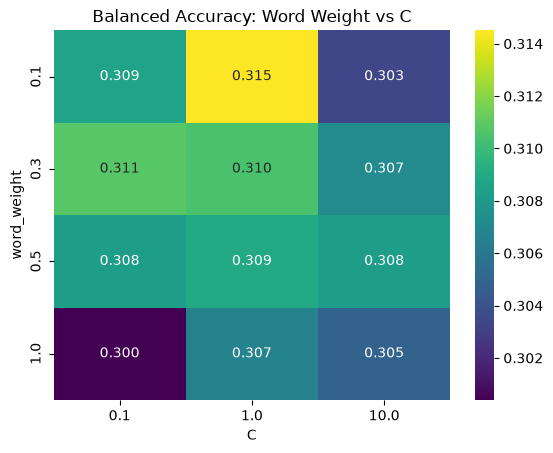

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

pivot = tuning_results.pivot(
    index="word_weight",
    columns="C",
    values="mean",
)

sns.heatmap(pivot, annot=True, fmt=".3f", cmap="viridis")
plt.title("Balanced Accuracy: Word Weight vs C")
plt.show()

## 9. Check whether length effects hold within classes

In [15]:
length_analysis = analysis.copy()

length_analysis["text_length"] = (
    length_analysis["text"].fillna("").str.len()
)

# Split texts by the median length within each class
class_median = length_analysis.groupby("model")[
    "text_length"
].transform("median")

length_analysis["length_group"] = np.where(
    length_analysis["text_length"] < class_median,
    "short",
    "long",
)

results = (
    length_analysis
    .groupby(["model", "length_group"])
    .agg(
        n=("model", "size"),
        char_accuracy=("char_correct", "mean"),
        both_accuracy=("both_correct", "mean"),
    )
    .reset_index()
)

display(results)

,model,length_group,n,char_accuracy,both_accuracy
0,claude-fable-5,long,75,0.146667,0.133333
1,claude-fable-5,short,74,0.054054,0.054054
2,claude-opus-4-6,long,75,0.493333,0.480000
3,claude-opus-4-6,short,75,0.333333,0.333333
4,claude-opus-4-8,long,75,0.266667,0.266667
5,claude-opus-4-8,short,75,0.213333,0.213333
6,claude-opus-5,long,75,0.746667,0.733333
7,claude-opus-5,short,75,0.506667,0.480000
8,claude-sonnet-5,long,76,0.276316,0.276316
9,claude-sonnet-5,short,74,0.189189,0.202703


In [16]:
comparison = results.pivot(
    index="model",
    columns="length_group",
    values="char_accuracy",
)

comparison["difference"] = (
    comparison["long"] - comparison["short"]
)

display(
    comparison.sort_values("difference", ascending=False)
)

print(
    "Classes where long texts perform better:",
    (comparison["difference"] > 0).sum(),
    "/",
    len(comparison),
)

length_group,long,short,difference
model,,,
claude-opus-5,0.746667,0.506667,0.240000
gpt-5.6-terra,0.360000,0.146667,0.213333
gpt-5.6-luna,0.360000,0.160000,0.200000
gpt-6-astra,0.573333,0.386667,0.186667
kimi-k3,0.306667,0.133333,0.173333
claude-opus-4-6,0.493333,0.333333,0.160000
gemini-3.7-flash,0.466667,0.320000,0.146667
qwen3.8-max,0.346667,0.240000,0.106667
gpt-5.6-sol,0.200000,0.093333,0.106667


Classes where long texts perform better: 15 / 18


## 10. Conclusions

### Key Findings

- **Char TF-IDF performs best**, achieving 0.3156 balanced accuracy, compared to 0.2630 for Word TF-IDF.
- **Combining Word and Char does not improve performance.** Reducing Word's weight helps, but the best combined result (0.3145) still falls slightly below Char alone.
- **Punctuation matters.** Removing punctuation reduces balanced accuracy from 0.3156 to 0.2771, suggesting that formatting and punctuation contain useful authorship signals.
- **Longer texts are easier to classify.** Accuracy increases with text length, and this pattern holds within 15 of 18 classes.
- **Similar model versions are frequently confused**, particularly within the Gemini and GPT families.

### Interpretation

Character n-grams appear to capture useful stylistic patterns beyond individual words. However, the experiments do not establish which specific features drive the predictions.

### Next Steps

- Compare different character n-gram ranges.
- Investigate which features contribute most to predictions.
- Validate promising configurations on unseen prompts to avoid overfitting to cross-validation results.